# DQN Modèle

Ce notebook sert à l'initialisation et à l'entrainement du modèle DQN à l'atterrissage du modèle lunaire.
Le Deep Q-Network (DQN) est un algorithme d'apprentissage par renforcement (Deep Reinforcement Learning). Il combine le Q-learning traditionnel avec les réseaux de neurones profonds. En effet, en Q-learning classique, les valeurs de Q(s, a) (c'est la qualité de a dans un état s), sont stoké dans une Q-Table. Cette table permet de stocké tous les états possible du système. Cependant, ici, avec notre modèle lunaire et ses 8 paramètres, le nombre d'état est techniquement infini (largement trop grand pour être stocké dans une table). Le DQN va donc transformer cette table en réseau de neurones. Le but de se réseau est d'estimer les valeurs Q.

## Import
Nous importons dans cette section toute les librairie qui nous serons utiles pour effectuer l'entrainement ou la justification des résultats

In [119]:
import gymnasium as gym                     # gymnasium : Bibliothèque Python open-source utilisée pour développer et tester des algorithmes d'apprentissage par renforcement.
import csv                                  # csv : Permet de sauvegarder les résultats des entrainements dans un CSV afin de les réutiliser pour des graphiques par exemples.
from pathlib import Path                    # pathlib : Permet d'aller chercher un fichier pour le modifier, écrire dedans et donc sauvergarder les résultats des entrainements.
import matplotlib.pyplot as plt             # matplotlib : Permet de créer et tracer des graphiques afin d'afficher et de justifier visuellement les résultats, voir l'évolutions des données et comprendre le fonctionnement de nos modèles.
import torch                                # torch : Bibliothèque logicielle open source utilisée pour développer et entraîner des modèles d'intelligence artificielle et de deep learning.
import torch.nn as nn                       # nn : Sert à entraîner des intelligences artificielles dans notre cas, prédire des données en imitant le fonctionnement du cerveau humain.
from collections import deque               # deque : Sert à stocker une liste d'éléments en permettant d'ajouter ou de supprimer des objets très rapidement des deux côtés.
import random                               # random : Permet de choisir des élements aléatoire comme pour l'Epsilon-Greedy, le Replay Buffer ou encore la seed d'entrainement.
import torch.optim as optim                 # optim : Module de PyTorch qui regroupe tous les algorithmes d'optimisation (comme le "adam" que nous utilisons).
import numpy as np                          # numpy : Permet d'effectuer des tableaux de valeurs avec des dimensions très élevées.

## Un épisode aléatoire
Afin, d'abord d'appréhender le modèle lunaire et les fonctionnalité de machine learning, nous effectuons un premier essai via un épisode aléatoire. Cela nous permet de voir l'efficacité du modèle, son fonctionnement, son environnement etc. L'idée va être de pouvoir mieux comprendre et modifier ses paramètres en connaissant correctement ses fonctionnalités. 

In [120]:
env = gym.make("LunarLander-v3")

etat_actuel, info = env.reset(seed=42)

total_reward = 0.0
steps = 0

while True:
    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    etat_actuel = next_state

    if terminated or truncated:
        break

print("Score total :", total_reward)
print("Nombre de pas :", steps)
print("Terminé :", terminated)
print("Interrompu :", truncated)

env.close()

Score total : -207.61757285951043
Nombre de pas : 129
Terminé : True
Interrompu : False


On voit que les resultat ne sont pas très bon, le modèle faisant des actions aléatoirement fini par se crasher ou sortir de l'écran très rapidement.

## Plusieurs épisodes aléatoires
Pour s'assurer que ce n'est pas un coup de malchance, nous décidons d'effectuer 100 essai aléatoire, le même nombre d'essai que le nombre final d'essai sur lequel notre modèle sera évalué.

### Raison de fin
Afin de voir de quelle manière les 100 essais aléatoire se terminent, nous créons une fonction qui renvoie la manière dont l'essai c'est terminé. Cela nous permet de savoir combien de fois le module c'est cracher, est sorti de l'écran ou bien à mis trop de temps à se terminer.

In [121]:
def end_reason(truncated, next_state, reward):
    if truncated:
        return "truncated"
    if abs(next_state[0]) >= 1.0:
        return "out_of_viewport"
    if reward == 100:
        return "at_rest"
    return "crash"

### Boucle d'entrainement aléatoire
Ici, l'entrainement est similaire au précédent, on va simplement rajouter une boucle for pour effectuer les N-episodes. On stocke les différentes étapes avec les récompenses pour pouvoir faire des graphiques.

In [122]:
# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
N_EPISODES = 100

# Création de l'environnement sans affichage graphique
env = gym.make("LunarLander-v3")

# Initialisation de la graine aléatoire
env.reset(seed=42)
env.action_space.seed(42)

# On va créer un CSV afin de sauvergarder les résultats
fichier_final = Path("results_random.csv")

# Liste qui contiendra les résultats des épisodes
results = []
raison_de_fin = {"truncated" : 0, "out_of_viewport" : 0, "at_rest" : 0, "crash" : 0}

# Exécution des épisodes
for episode in range(1, N_EPISODES + 1):

    # Démarrage d'un nouvel épisode
    etat_actuel, info = env.reset()

    # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
    recompense_totale = 0.0
    steps = 0

    # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
    terminated = False
    truncated = False

    # L'agent joue jusqu'à la fin de l'épisode
    while not (terminated or truncated):

        # Choix d'une action aléatoire
        action = env.action_space.sample()

        # Exécution de l'action (on sauvergarde chaque info qu'engendre l'action comme la position, la récompense ou savoir si le module a terminé d'une quelconque façon)
        next_state, reward, terminated, truncated, info = env.step(action)

        # Mise à jour des statistiques
        recompense_totale += reward
        steps += 1

        # Passage au nouvel état
        etat_actuel = next_state

    # On enregistre les résultats de l'épisode
    result = {
        "episode": episode,
        "reward": round(recompense_totale, 2),
        "steps": steps,
        "terminated": terminated,
        "truncated": truncated
    }

    results.append(result)
    raison_de_fin[end_reason(truncated, next_state, reward)] += 1

    # Affichage du résultat
    print(f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

# Fermeture de l'environnement
env.close()

# Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques
with fichier_final.open("w", newline="", encoding="utf-8") as file:

    # Création des 5 colonnes qui sont les différentes paramètres du modèle
    colonnes = ["episode", "reward", "steps", "terminated", "truncated"]

    writer = csv.DictWriter(file, fieldnames=colonnes)

    # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
    writer.writeheader()
    writer.writerows(results)

# Calcul des statistiques globales
mean_reward = sum(r["reward"] for r in results) / len(results)

print("\n------- BILAN -------")
print(f"Nombre d'épisodes : {N_EPISODES}")
print(f"Récompense moyenne : {mean_reward:.2f}")

print(f"Raison de fin : {raison_de_fin}")

Épisode 1/100 | Récompense obtenue : -108.55 | Pas utilisés pour terminé : 106 | Terminé ? : True | Interrompu ? : False
Épisode 2/100 | Récompense obtenue : -117.45 | Pas utilisés pour terminé : 75 | Terminé ? : True | Interrompu ? : False
Épisode 3/100 | Récompense obtenue : -304.18 | Pas utilisés pour terminé : 62 | Terminé ? : True | Interrompu ? : False
Épisode 4/100 | Récompense obtenue : -113.35 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 5/100 | Récompense obtenue : -108.74 | Pas utilisés pour terminé : 105 | Terminé ? : True | Interrompu ? : False
Épisode 6/100 | Récompense obtenue : -295.99 | Pas utilisés pour terminé : 87 | Terminé ? : True | Interrompu ? : False
Épisode 7/100 | Récompense obtenue : -116.40 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 8/100 | Récompense obtenue : -222.88 | Pas utilisés pour terminé : 143 | Terminé ? : True | Interrompu ? : False
Épisode 9/100 | Récompense obtenue 

## Graphiques des résultats
Pour pouvoir regarder visuellement les résultats, on effectue des graphiques. Nous avons fait un graphique qui affiche les récompenses reçues par nombre d'épisode. Le but de notre futur entrainement est d'avoir une moyenne de scores de 200 sur 100 épisodes. Ici on voit que le meilleur score n'atteind même pas 0. Ensuite nous avons fait un graphiques qui affiches le nombre des différentes façon de terminer un épisode. Il n'y a aucun épisode terminer car le module c'est posé ou à pris trop de temps. Mais on voit surtout que la majorité des essai se termine par un crash.
On comprend donc l'importance de l'entrainement. Et surtout que l'aléatoire ne permet pas au modèle d'avoir des résultats satisfaisants. 

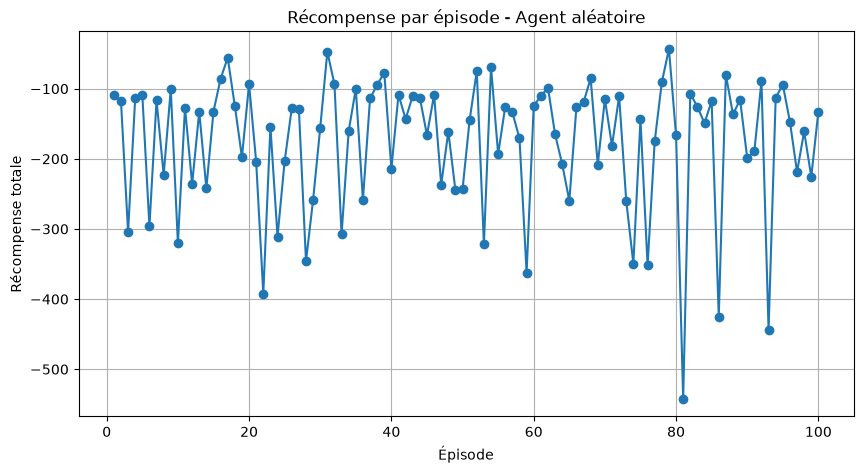

In [144]:
# On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les récompenses par épisode)
episodes_aléatoire = []
rewards_aléatoire = []

# Lecture du fichier CSV
with open("results_random.csv", "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    # Pour chaque ligne du CSV, on ajoute l'épisode et la récompense associée, à la liste    
    for row in reader:
        episodes_aléatoire.append(int(row["episode"]))
        rewards_aléatoire.append(float(row["reward"]))

# Création du graphique
plt.figure(figsize=(10, 5))

# Ordonnées episodes, Abscisses récompenses
plt.plot(episodes_aléatoire, rewards_aléatoire, marker="o")

# Légende du graphique (titre, label X, label Y)
plt.title("Récompense par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

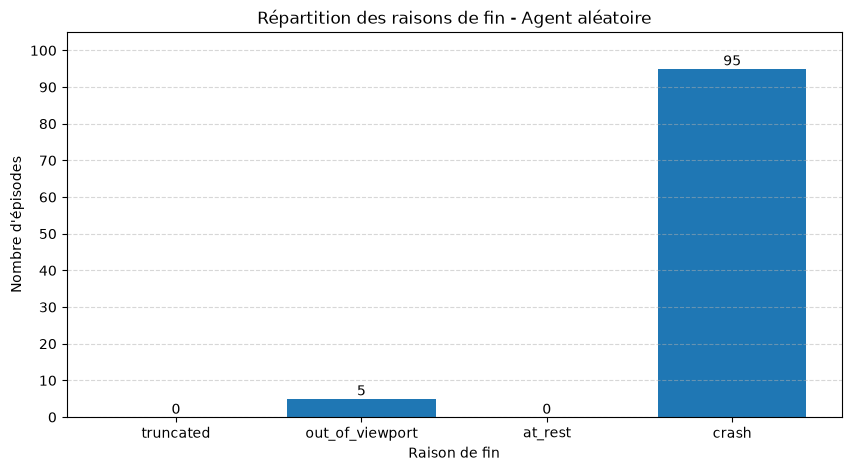

In [124]:
# Création du graphique des raisons de fin
plt.figure(figsize=(10, 5))

raisons = list(raison_de_fin.keys())
nombres = list(raison_de_fin.values())

plt.bar(raisons, nombres)

plt.title("Répartition des raisons de fin - Agent aléatoire")
plt.xlabel("Raison de fin")
plt.ylabel("Nombre d'épisodes")

# Afficher le nombre au-dessus de chaque barre
for i, nombre in enumerate(nombres):
    plt.text(i, nombre, str(nombre), ha="center", va="bottom")

plt.yticks(range(0, N_EPISODES + 1, 10))
plt.ylim(0, N_EPISODES + 5)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

## Entrainement DQN

Nous effectuons donc l'entrainement du modèle DQN, nous commencerons par initialiser toutes les étapes nécessaire au fonctionnement de la boucle, pour ensuite construire celle-ci sur le modèle aléatoire, mais en enlevant tous les éléments alétoire de celui-ci. Le DQN à besoin de plusieurs éléments que nous définissons ici pour fonctionner : 

- Un environnement Pytorch
- L'Espilon-greedy
- Le Replay Buffer
- Et un Train-Step

### Création de l'environnement PyTorch
L'environnement PyTorch va être l'endroit ou le modèle va être entrainé. Il permet de créer un réseau de neurone, qui va être utilisé par le modèle pour effectué ses entrainements.

In [125]:
class DQN(nn.Module):
    def __init__(self, state_size=env.observation_space.shape[0], action_size=env.action_space.n):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)

### Epsilon-greedy

Epsilon-greedy est la fonction qui donne au modèle sa façon d'apprendre. On vient modifier l'hyperparamètre Epsilon ε, il oscillent entre 0 et 1. C'est la probabilité avec laquelle il va effectué une action aléatoirement ou une action grâce à son entrainement. Plus ε est élevé, plus ils à de chances de faire une action aléatoire. Au départ, on met ε à 1 car ils n'a pas encore d'expériences en mémoire. Il n'a donc pas encore besoin de passé par de l'exploitation, il reste donc en exploration. A chaque étape, on va venir diminuer tout doucement l'epsilon afin que petit à petit, il ne fasse des choix que via ses expériences passées. 

In [ ]:
def select_action(state, model, epsilon, action_size=env.action_space.n):
    # Exploration : choisir une action au hasard
    if random.random() < epsilon:
        return random.randrange(action_size)

    # Exploitation : choisir la meilleure action selon le réseau
    with torch.no_grad():
        state = torch.tensor(state, dtype=torch.float32)
        q_values = model(state)

    return torch.argmax(q_values).item()

### ReplayBuffer
Et justement, Replay Buffer permet de gérer cette mémoire d'expérience passé. Replay Buffer à une capacité maximum de stockage, qui quand elle est dépassée, enlève les plus anciennes données pour les remplacer par les nouvelles. Lorsque, grâce à l'Epsilon, le choix de la prochaine action doit être faite via les anciennes expériences. Nous allons utiliser la méthode "sample", qui va récupérer un nombre n d'expériences aléatoirement, afin de ne pas donner aux modèles des expériences qui soient trop proches ou trop éloignées de son état actuel.

In [127]:
class ReplayBuffer:

  def __init__(self, capacity):
    self.buffer = deque(maxlen=capacity)

  def __len__(self):
    return len(self.buffer)

  def add(self, experience):
    self.buffer.append(experience)

  def sample(self, batch_size):
    return random.sample(self.buffer, batch_size)

### Train Step
Ici, c'est l'étape d'apprentissage de notre agent DQN. Elle sélectionne aléatoirement un lot d'expériences dans le Replay Buffer, calcule les valeurs Q prédites et les valeurs cibles, mesure l'erreur avec la fonction MSE, puis met à jour les paramètres du réseau principal grâce à la rétropropagation et à l'optimiseur.

In [128]:
BATCH_SIZE = 50
GAMMA = 0.99

def train_step(model, buffer, target_model, loss_fn, optimizer):

    # On attend d'avoir assez d'expériences pour former un lot
    if len(buffer) < BATCH_SIZE:
        return None

    # On va venir récupérer le nombre d'expériences de manière aléatoire
    batch = buffer.sample(BATCH_SIZE)

    # On va ensuite séparer les expériences via les paramètres (le zip permet de régrouper tous les élémets de "batch" en un point)
    states, actions, rewards, next_states, terminated, truncated = zip(*batch)

    # Puis on va convertir ces paramètres en tenseurs PyTorch (utilisable par le modèle)
    states = torch.as_tensor(np.asarray(states), dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64).unsqueeze(1)
    rewards = torch.tensor(rewards, dtype=torch.float32)
    next_states = torch.as_tensor(np.asarray(next_states), dtype=torch.float32)
    terminated = torch.tensor(terminated, dtype=torch.float32)

    # 4. Prédictions du réseau principal pour les actions effectuées
    current_q_values = model(states).gather(1, actions).squeeze(1)

    # On calcule les valeurs cibles avec le réseau cible
    with torch.no_grad():
        next_q_values = target_model(next_states)
        max_next_q_values = next_q_values.max(dim=1).values
        target_q_values = (rewards + GAMMA * (1 - terminated) * max_next_q_values)

    # Et on calcule la fonction de perte MSE
    loss = loss_fn(current_q_values, target_q_values)

    # Mise à jour des paramètres du réseau principal
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # Et enfin, on renvoie la valeur de la perte pour pouvoir la suivre
    return loss.item()

### Entrainement du modèle
C'est la boucle d'entrainement du modèle DQN. On assemble tous les éléments que l'on a initialisés avant, dans cette partie.
On va tester avec 1150 épisodes. 
On met bien le Epsilon à 1 au début et à chaque épisode je le multiplie par EPSILON_DECAY.
On fixe une graine que l'on va entrer dans tous les éléments qui utilise de l'aléatoire ce qui va venir chercher une reproductibilité au maximum.
On y voit l'initialisation du modèle, la préparation des variables et enfin la boucle qui utilise le buffer, la fonction de perte ou encore l'epsilon.

In [ ]:
def train_dqn(seed):# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
    N_EPISODES = 1150

    TARGET_UPDATE = 250
    steps_done = 0

    # On va venir définir nos variables pour Epsilon afin que celui-ci commence à 1 pour qu'il ne tente pas d'utiliser des expériences qui n'existent pas encore.
    epsilon = 1.0
    EPSILON_MIN = 0.05          # On défini un minimum pour éviter que l'agent ne se fige dans une stratégie.
    EPSILON_DECAY = 0.997       # Et on défini un constante qui permette de décrémenter l'epsilon petit à petit.

    # On défini une seed et on la fixe à tous les éléments qui utilise de l'aléatoire. Cela va permettre de s'approcher aux mieux d'une reproductibilté parfaite
    random.seed(seed) 
    np.random.seed(seed) 
    torch.manual_seed(seed)

    # Création de l'environnement sans affichage graphique
    env = gym.make("LunarLander-v3")

    # Initialisation de la graine aléatoire
    env.reset(seed=seed)
    env.action_space.seed(seed)

    # Liste qui contiendra les résultats des épisodes
    results = []
    raison_de_fin_dqn = {"truncated" : 0, "out_of_viewport" : 0, "at_rest" : 0, "crash" : 0}

    epsilon_history = []
    loss_history = []

    # Création du modèle DQN
    model = DQN()

    # Création du modèle cible qui va servir de référence et de comparaison pour le modèle (on l'initialise avec les mêmes paramètres que notre modèle) 
    target_model = DQN()
    target_model.load_state_dict(model.state_dict())

    # Création du buffer, c'est la manière avec laquelle le modèle va se souvenir des éléments.
    buffer = ReplayBuffer(100000)

    # L'optimiseur va permettre de modifier continuellement le modèle prinipal afin d'affiner au fil du temps le résultat.
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Création de la loss fonction avec la Mean Squared Error (MSE) qui va comparer la valeur prédite de la valeur cible. 
    loss_fn = nn.MSELoss()

    # Exécution des épisodes
    for episode in range(1, N_EPISODES + 1):

        # Démarrage d'un nouvel épisode
        etat_actuel, info = env.reset()

        # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
        recompense_totale = 0.0
        steps = 0

        # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
        terminated = False
        truncated = False

        # L'agent joue jusqu'à la fin de l'épisode
        while not (terminated or truncated):

            # Initialisation du choix de l'action
            action = select_action(etat_actuel, model, epsilon)

            # Execution de l'action
            next_state, reward, terminated, truncated, info = env.step(action)

            experience = etat_actuel, action, reward, next_state, terminated, truncated
            
            # Enregistrement de la "frame actuel" (la position, les récompenses etc...)
            buffer.add(experience)

            # On met à jour les statistiques
            recompense_totale += reward
            steps += 1
            steps_done += 1

            # On entraîne le réseau principal tous les deux steps.
            if steps_done % 2 == 0:
                loss = train_step(model, buffer, target_model, loss_fn, optimizer)

                if loss is not None:
                    loss_history.append(loss)

            # On met à jour le réseau cible périodiquement
            if steps_done % TARGET_UPDATE == 0:
                target_model.load_state_dict(model.state_dict())

            # Et enfin on passe à l'état suivant
            etat_actuel = next_state

        reason = end_reason(truncated, next_state, reward)
        
        # On enregistre les résultats de l'épisode
        result = {
            "episode": episode,
            "reward": round(recompense_totale, 2),
            "steps": steps,
            "terminated": terminated,
            "truncated": truncated,
            "end_reason": reason
        }

        # On les ajoute dans la liste results
        results.append(result)

        raison_de_fin_dqn[end_reason(truncated, next_state, reward)] += 1

        # On diminue la pourcentage d'élément d'apprentissage pour s'entrainer de plus en plus
        epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
        epsilon_history.append(epsilon)

        # Affichage du résultat
        print(f"Seed utilisée {seed} | "f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

    # Fermeture de l'environnement
    env.close()

    # Calcul des statistiques globales
    mean_reward = sum(r["reward"] for r in results[-100:]) / len(results[-100:])

    print("\n------- BILAN -------")
    print(f"Nombre d'épisodes : {N_EPISODES}")
    print(f"Récompense moyenne : {mean_reward:.2f}")

    return {
        "seed": seed,
        "results": results,
        "end_reasons": raison_de_fin_dqn,
        "epsilon_history": epsilon_history,
        "loss_history": loss_history,
        "mean_reward": mean_reward,
        "model": model
    }

### Sauvegarde du modèle en .pth
Pour pouvoir évaluer le modèle une fois que celui-ci est sauvegardé. On va le sauvegarder en .pth. C'est le format de la bibliothèque de PyTorch pour sauvegarder et charger des fichiers.

In [130]:
seeds = [42, 118, 90, 3]
entrainements_dqn = {}

for k in seeds:

    # On va créer un CSV afin de sauvergarder les résultats
    fichier_final = Path(f"results_DQN_{k}.csv")

    entrainement_dqn_seed_k = train_dqn(k)
    entrainements_dqn[k] = entrainement_dqn_seed_k

    # Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques et les tests finaux
    with fichier_final.open("w", newline="", encoding="utf-8") as file:

        # Création des 5 colonnes qui sont les différentes paramètres du modèle
        colonnes = ["episode", "reward", "steps", "terminated", "truncated", "end_reason", "epsilon", "loss"]

        writer = csv.DictWriter(file, fieldnames=colonnes)

        # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
        writer.writeheader()
        writer.writerows(entrainement_dqn_seed_k["results"])
    
    torch.save(entrainement_dqn_seed_k["model"].state_dict(), f"lunarlander_dqn_seed_{k}.pth")

    print(f"Modèle seed : {k} sauvegardé !")

Seed utilisée 42 | Épisode 1/1150 | Récompense obtenue : -87.47 | Pas utilisés pour terminé : 117 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 2/1150 | Récompense obtenue : -339.71 | Pas utilisés pour terminé : 108 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 3/1150 | Récompense obtenue : -306.34 | Pas utilisés pour terminé : 91 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 4/1150 | Récompense obtenue : -141.03 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 5/1150 | Récompense obtenue : -234.43 | Pas utilisés pour terminé : 97 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 6/1150 | Récompense obtenue : -146.05 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 7/1150 | Récompense obtenue : -136.79 | Pas utilisés pour terminé : 103 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 |

# Graphiques sur le modèle DQN
Pour voir l'avancé et l'amélioration du modèle au cours des entrainements, on trace un graphique qui permette de voir l'évolution de tous les paramètres les plus importants au cours des différents épisodes des différentes seeds.

## Graphiques "Récompense réçu par le modèle dans chaque épisode"

Ces graphiques servent à montrer l'évolution du modèle a travers ses récompenses reçu au long de son apprentissage.

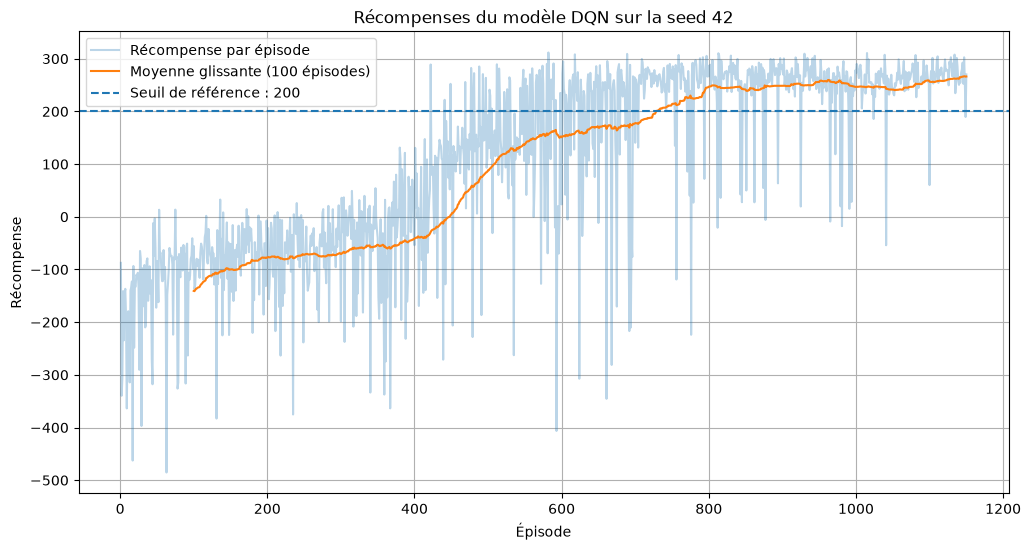

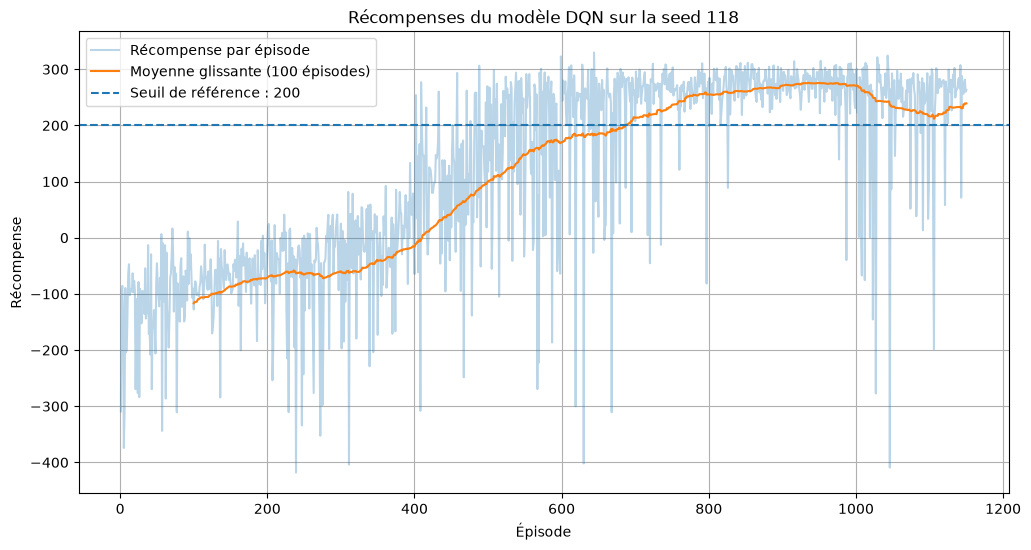

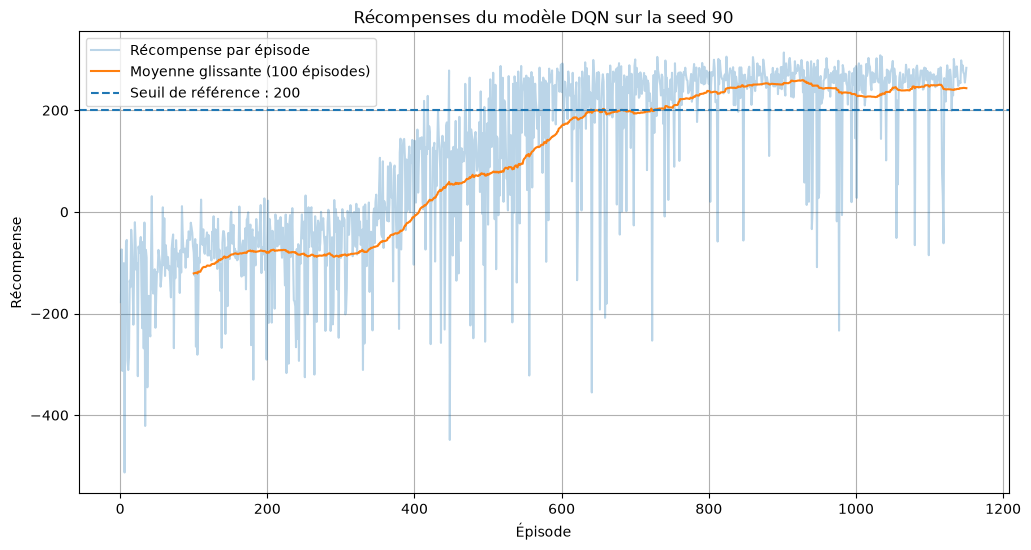

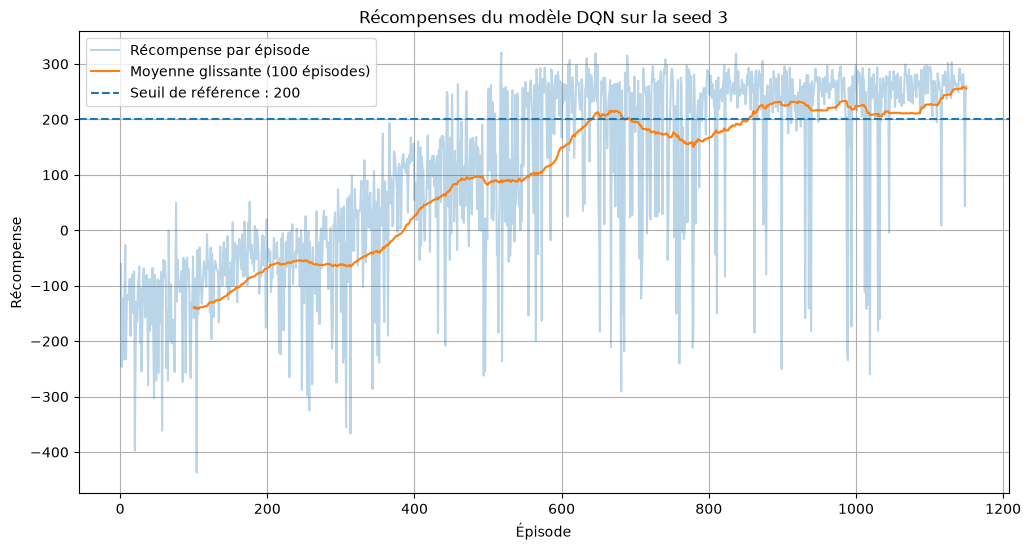

In [176]:
for k in seeds:

    fichier_final = Path(f"results_DQN_{k}.csv")

    with fichier_final.open("r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)

        episodes = []
        rewards = []

        for row in reader:
            episodes.append(int(row["episode"]))
            rewards.append(float(row["reward"]))

    moving_average = np.convolve(rewards, np.ones(100) / 100, mode="valid")

    plt.figure(figsize=(12, 6))

    plt.plot(episodes,rewards, alpha=0.3, label="Récompense par épisode")
    plt.plot(episodes[100 - 1:], moving_average, label="Moyenne glissante (100 épisodes)")
    plt.axhline(y=200,linestyle="--",label="Seuil de référence : 200")

    plt.xlabel("Épisode")
    plt.ylabel("Récompense")
    plt.title(f"Récompenses du modèle DQN sur la seed {k}")
    plt.legend()

    plt.grid(True)
    plt.show()

## Graphiques "Fin du modèle durant les épisodes"

Pour également voir l'amélioration du modèle au cours des entrainements, on affiche la fin de chaque épisode pour voir de quelle manière celui-ci c'est terminé (si c'est par un crash, un truncated ou qu'il s'est posé par exemple)

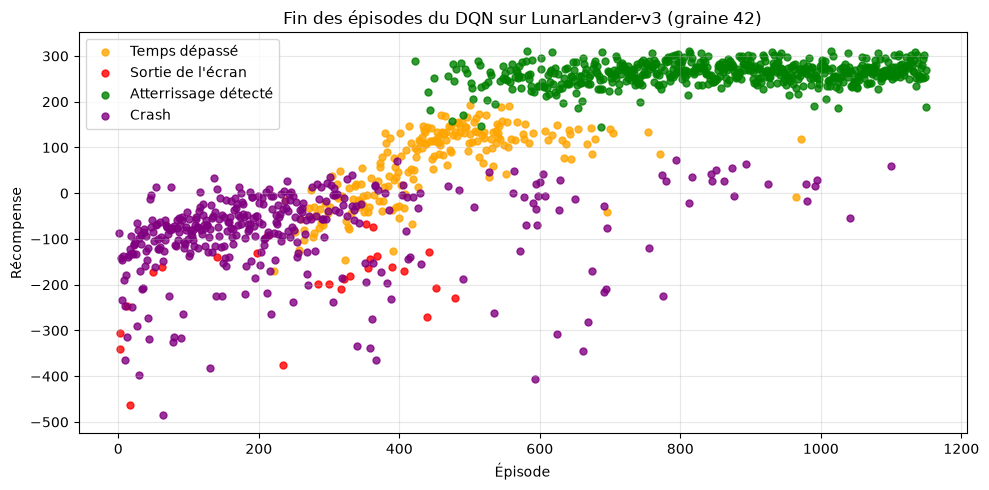

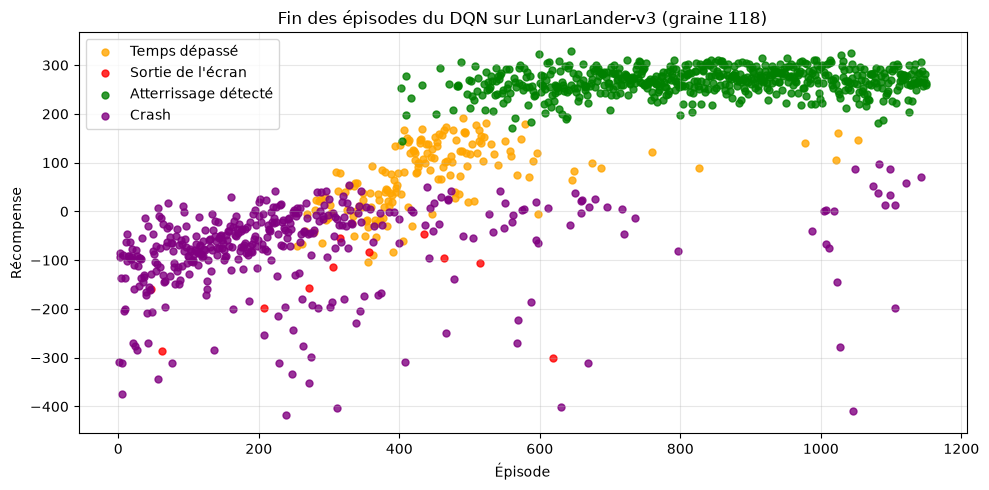

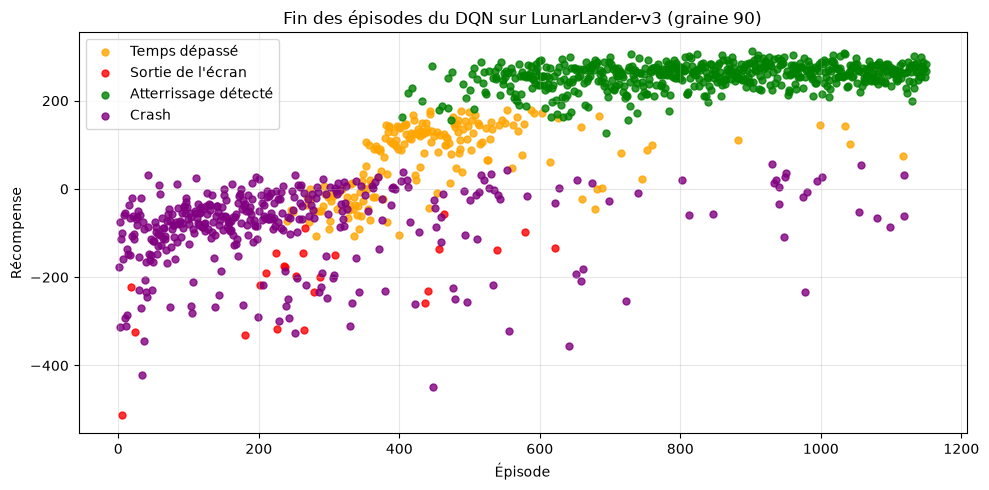

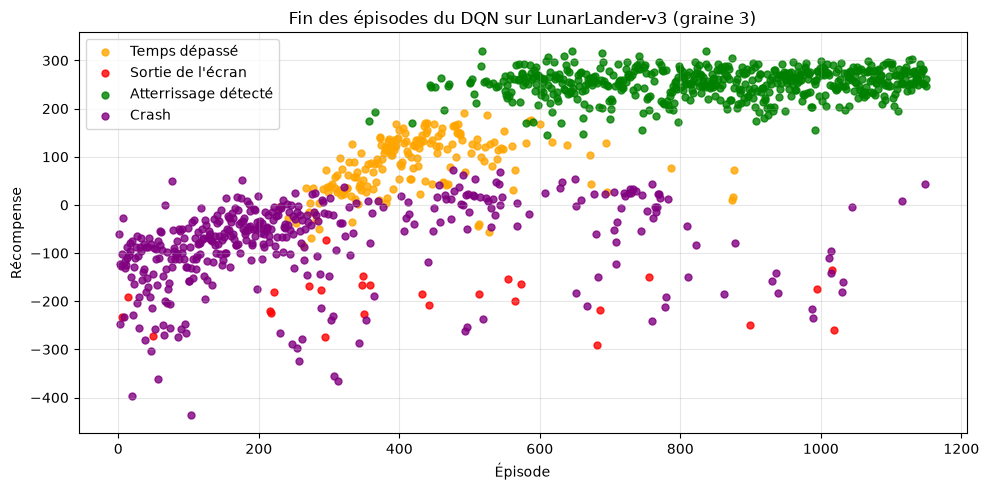

In [132]:
# Catégories de fin d'épisode
colors = {
    "truncated": "orange",
    "out_of_viewport": "red",
    "at_rest": "green",
    "crash": "purple"
}

labels = {
    "truncated": "Temps dépassé",
    "out_of_viewport": "Sortie de l'écran",
    "at_rest": "Atterrissage détecté",
    "crash": "Crash"
}

for k in seeds:

    # Lire les résultats du CSV correspondant à la graine
    fichier_final = Path(f"results_DQN_{k}.csv")

    with fichier_final.open("r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)
        results = []

        for row in reader:
            results.append({
                "episode": int(row["episode"]),
                "reward": float(row["reward"]),
                "end_reason": row["end_reason"]
            })

    plt.figure(figsize=(10, 5))

    # Ajouter un point pour chaque épisode, selon sa fin
    for reason, color in colors.items():

        x = [
            result["episode"]
            for result in results
            if result["end_reason"] == reason
        ]

        y = [
            result["reward"]
            for result in results
            if result["end_reason"] == reason
        ]

        if x:
            plt.scatter(
                x,
                y,
                color=color,
                label=labels[reason],
                s=25,
                alpha=0.8
            )

    plt.xlabel("Épisode")
    plt.ylabel("Récompense")
    plt.title(f"Fin des épisodes du DQN sur LunarLander-v3 (graine {k})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Graphiques "Répartition des fins pour chaque seed"

Ici, on veut obtenir plus d'informations sur les différentes fin et le nombre d'itérations où elles se sont chacune produite. Cela nous permet de savoir de quelle manière le modèle fini le plus ses épisodes.

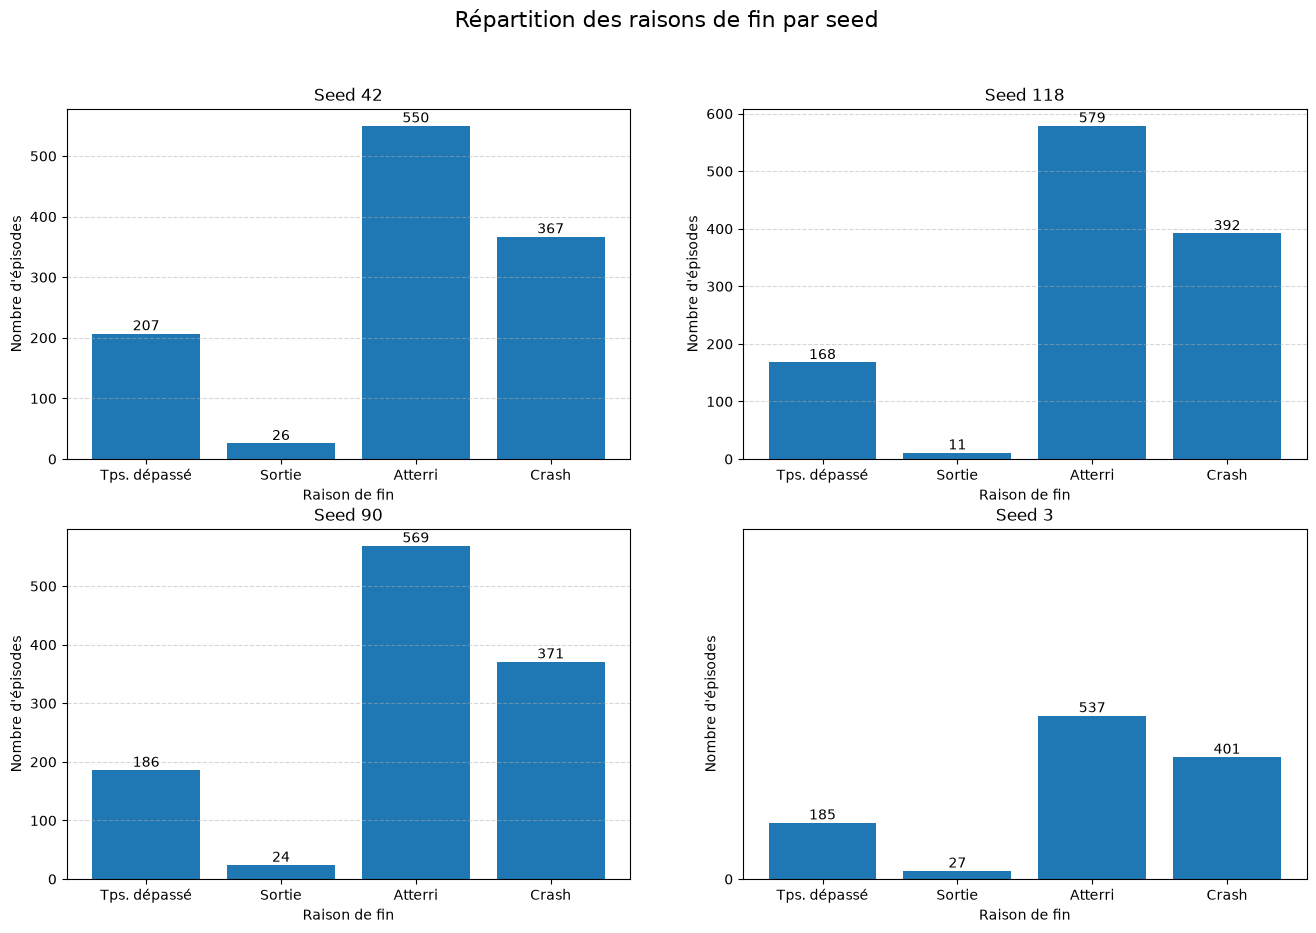

In [ ]:
# Catégories de fin d'épisode
labels = {
    "truncated": "Tps. dépassé",
    "out_of_viewport": "Sortie",
    "at_rest": "Atterri",
    "crash": "Crash"
}

# Création du graphique des raisons de fin
n_seeds = len(seeds)
n_cols = 2
n_rows = (n_seeds + n_cols - 1) // n_cols

# Créer une seule figure avec plusieurs graphiques
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 10))

axes = np.array(axes).flatten()

for i, k in enumerate(seeds):

    fichier_final = Path(f"results_DQN_{k}.csv")

    # Lire les résultats du CSV
    with fichier_final.open("r", newline="", encoding="utf-8") as file:
        reader = csv.DictReader(file)

        end_reasons = {
            "truncated": 0,
            "out_of_viewport": 0,
            "at_rest": 0,
            "crash": 0
        }

        for row in reader:
            reason = row["end_reason"]

            if reason in end_reasons:
                end_reasons[reason] += 1

    # Préparer les données du graphique
    raisons = [labels[reason] for reason in end_reasons]
    nombres = list(end_reasons.values())

    ax = axes[i]
    ax.bar(raisons, nombres)

    ax.set_title(f"Seed {k}")
    ax.set_xlabel("Raison de fin")
    ax.set_ylabel("Nombre d'épisodes")
    ax.tick_params(axis="x")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    # Afficher le nombre au-dessus de chaque barre
    for i, nombre in enumerate(nombres):
        ax.text(i, nombre, str(nombre), ha="center", va="bottom")

    plt.xlabel("Raison de fin")
    plt.ylabel("Nombre d'épisodes")


    plt.yticks(range(0, 100 + 1, 1150))
    plt.ylim(0, 1150)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    
fig.suptitle("Répartition des raisons de fin par seed", fontsize=16)
plt.show()

## Graphiques "Nombre de pas du modèle"

Le modèle à 1000 pas maximum pour terminer un épisode sous peine d'être tronquer. Nous voulons savoir sur un moyenne glissante de 100 épisodes le nombres de pas nécessaire au modèle pour terminer ses épisodes.

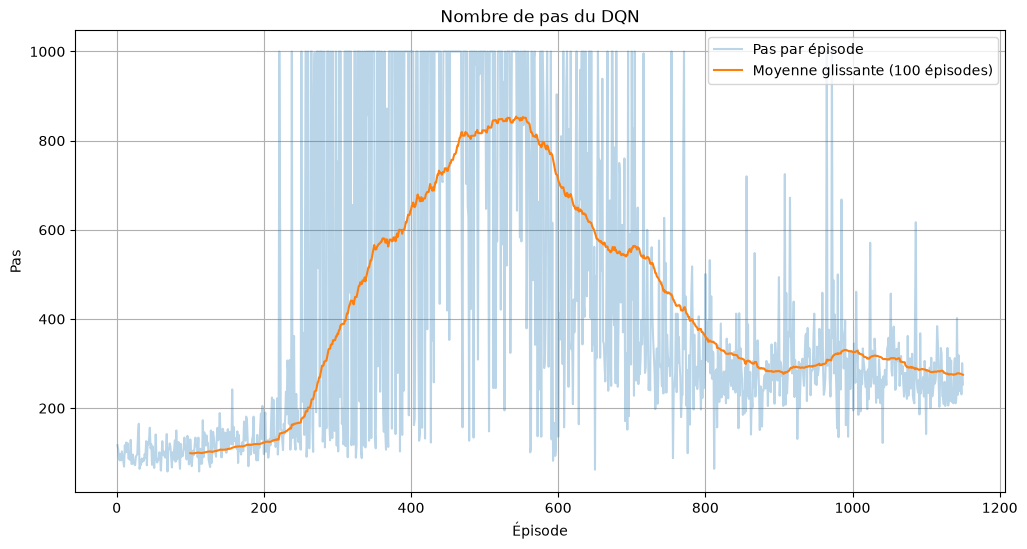

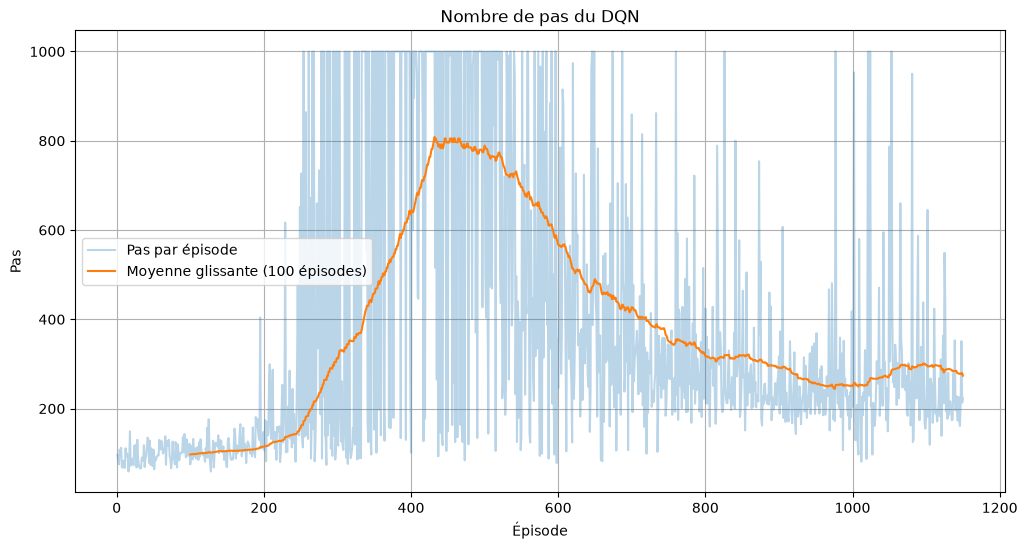

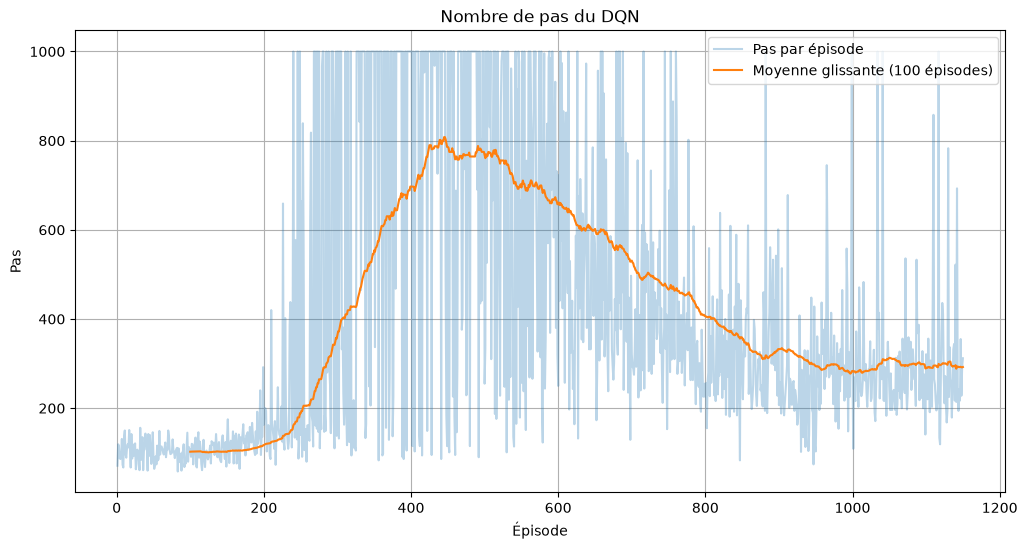

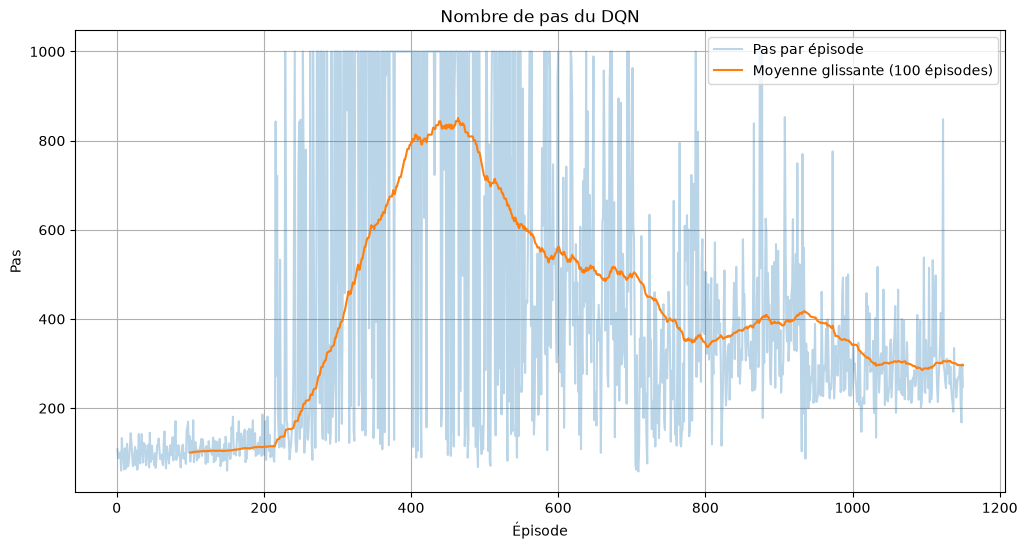

In [155]:
for k in seeds:

    fichier_final = Path(f"results_DQN_{k}.csv")

    with fichier_final.open("r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)

        episodes = []
        steps_history = []

        for row in reader:
            episodes.append(int(row["episode"]))
            steps_history.append(float(row["steps"]))
            
    moving_average = np.convolve(steps_history, np.ones(100) / 100, mode="valid")

    plt.figure(figsize=(12, 6))

    plt.plot(episodes,steps_history, alpha=0.3, label="Pas par épisode")
    plt.plot(episodes[100 - 1:], moving_average, label="Moyenne glissante (100 épisodes)")

    plt.xlabel("Épisode")
    plt.ylabel("Pas")
    plt.title("Nombre de pas du DQN")
    plt.legend()

    plt.grid(True)
    plt.show()

## Graphiques "Évolutions de la fonction de loss pour chaque pas des épisodes"

Tout au long de l'entrainement, la fonction de loss calcul la différence entre les valeurs supposées et les valeurs réellement obtenu pour par la suite ajuster le modèle. Le but est de savoir si il n'y a pas de trop grandes différences entre les ces valeurs.

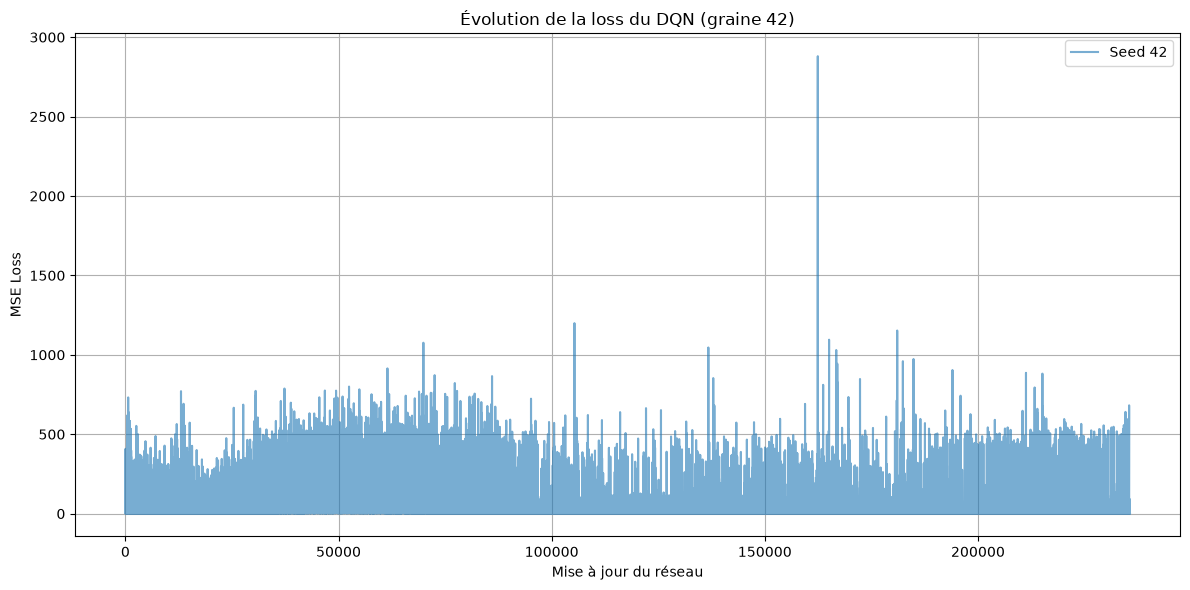

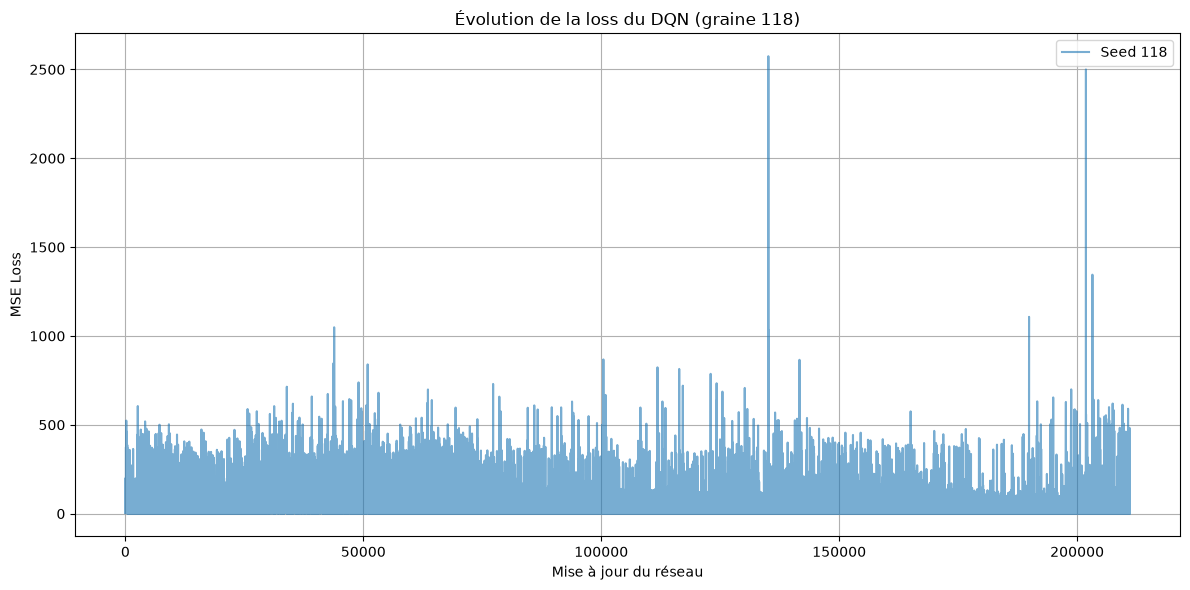

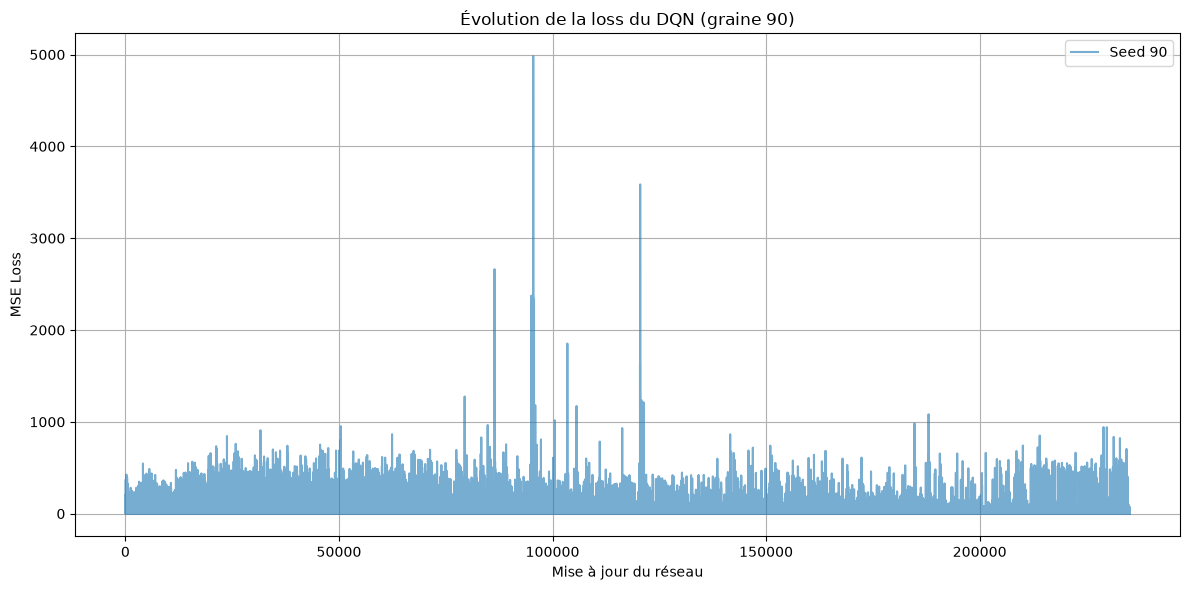

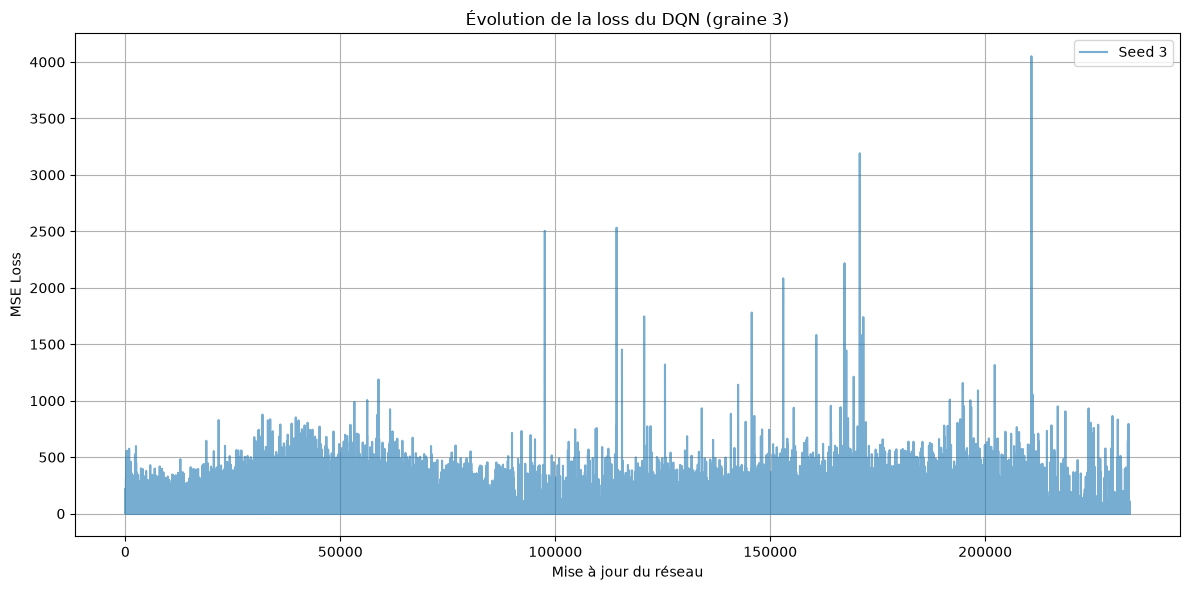

In [135]:
for k in seeds:

    loss_history = entrainements_dqn[k]["loss_history"]

    plt.figure(figsize=(12, 6))

    plt.plot(loss_history, alpha=0.6, label=f"Seed {k}")

    plt.xlabel("Mise à jour du réseau")
    plt.ylabel("MSE Loss")
    plt.title(f"Évolution de la loss du DQN (graine {k})")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Graphique "Évolution de l'Epsilon Greedy au long des épisodes"

Ici, pas besoin des plusieurs graphiques. L'epsilon greedy baisse de manière équivalente pour chaque entrainement. Ce graphique nous permet de voir l'avancée de l'epsilon sur le nombre d'épisode.

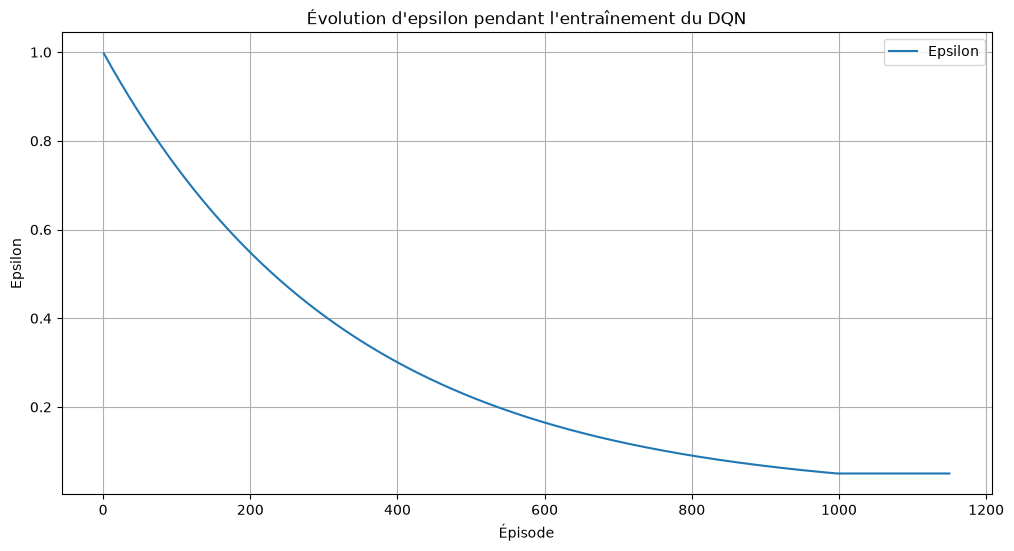

In [136]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(entrainement_dqn_seed_k["epsilon_history"]) + 1),
    entrainement_dqn_seed_k["epsilon_history"],
    label="Epsilon"
)

plt.xlabel("Épisode")
plt.ylabel("Epsilon")
plt.title("Évolution d'epsilon pendant l'entraînement du DQN")

plt.legend()
plt.grid(True)
plt.show()

# Évaluation finale des différentes seeds.

Ici, on viens évaluer les modèles DQN entrainer avec les différentes seeds. On met l'Epsilon à 0 pour qu'il n'y est plus du tout d'exploration et que l'évaluation ne se fasse que sur les expériences passés du modèles durant son expérience.

In [142]:
print("\n------- BILAN -------")

for j in seeds:# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
    N_EPISODES = 100

    # On va venir définir nos variables pour Epsilon afin que celui-ci commence à 1 pour qu'il ne tente pas d'utiliser des expériences qui n'existent pas encore.
    epsilon = 0.0
    # On défini une seed et on la fixe à tous les éléments qui utilise de l'aléatoire. Cela va permettre de s'approcher aux mieux d'une reproductibilté parfaite

    SEED = 42
    random.seed(SEED) 
    np.random.seed(SEED) 
    torch.manual_seed(SEED)

    # Création de l'environnement sans affichage graphique
    env = gym.make("LunarLander-v3")

    # Initialisation de la graine aléatoire
    env.action_space.seed(42)

    # On va créer un CSV afin de sauvergarder les résultats
    fichier_final = Path(f"results_DQN_evaluation_{j}.csv")

    # Liste qui contiendra les résultats des épisodes
    results = []
    raison_de_fin_dqn = {"truncated" : 0, "out_of_viewport" : 0, "at_rest" : 0, "crash" : 0}

    # Création du modèle DQN
    model = DQN()
    model.load_state_dict(torch.load(f"lunarlander_dqn_seed_{j}.pth", map_location="cpu"))
    model.eval()

    # Exécution des épisodes
    for episode in range(1, N_EPISODES + 1):

        # Démarrage d'un nouvel épisodeµ
        etat_actuel, info = env.reset(seed=SEED + episode - 1)

        # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
        recompense_totale = 0.0
        steps = 0

        # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
        terminated = False
        truncated = False

        # L'agent joue jusqu'à la fin de l'épisode
        while not (terminated or truncated):

            # Initialisation du choix de l'action
            action = select_action(etat_actuel, model, epsilon)

            # Execution de l'action
            next_state, reward, terminated, truncated, info = env.step(action)

            experience = etat_actuel, action, reward, next_state, terminated, truncated

            # On met à jour les statistiques
            recompense_totale += reward
            steps += 1

            # Et enfin on passe à l'état suivant
            etat_actuel = next_state

        reason = end_reason(truncated, next_state, reward)
        
        # On enregistre les résultats de l'épisode
        result = {
            "episode": episode,
            "reward": round(recompense_totale, 2),
            "steps": steps,
            "terminated": terminated,
            "truncated": truncated,
            "end_reason": reason
        }

        # On les ajoute dans la liste results
        results.append(result)

        raison_de_fin_dqn[end_reason(truncated, next_state, reward)] += 1

    # Fermeture de l'environnement
    env.close()

    # Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques et les tests finaux
    with fichier_final.open("w", newline="", encoding="utf-8") as file:

        # Création des 5 colonnes qui sont les différentes paramètres du modèle
        colonnes = ["episode", "reward", "steps", "terminated", "truncated", "end_reason"]

        writer = csv.DictWriter(file, fieldnames=colonnes)

        # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
        writer.writeheader()
        writer.writerows(results)

    # Calcul des statistiques globales
    mean_reward = sum(r["reward"] for r in results[-100:]) / len(results[-100:])

    print(f"Évaluation de la seed : {j}")
    print(f"Récompense moyenne : {mean_reward:.2f} \n")


------- BILAN -------
Évaluation de la seed : 42
Récompense moyenne : 276.38 

Évaluation de la seed : 118
Récompense moyenne : 271.21 

Évaluation de la seed : 90
Récompense moyenne : 231.77 

Évaluation de la seed : 3
Récompense moyenne : 254.54 



## Graphique Final "Comparaison de l'évaluation de tous les modèles DQN et l'aléatoire"

Ce graphique nous permet de voir que peut importe la seed, nos modèle DQN on plus ou moins les mêmes valeurs finales d'évaluation, et surtout que leurs moyenne est bien supérieur à 200 ce qui signifie que le modèle est fonctionnel, mais surtout qu'ils sont bien meilleurs que l'aléatoire.

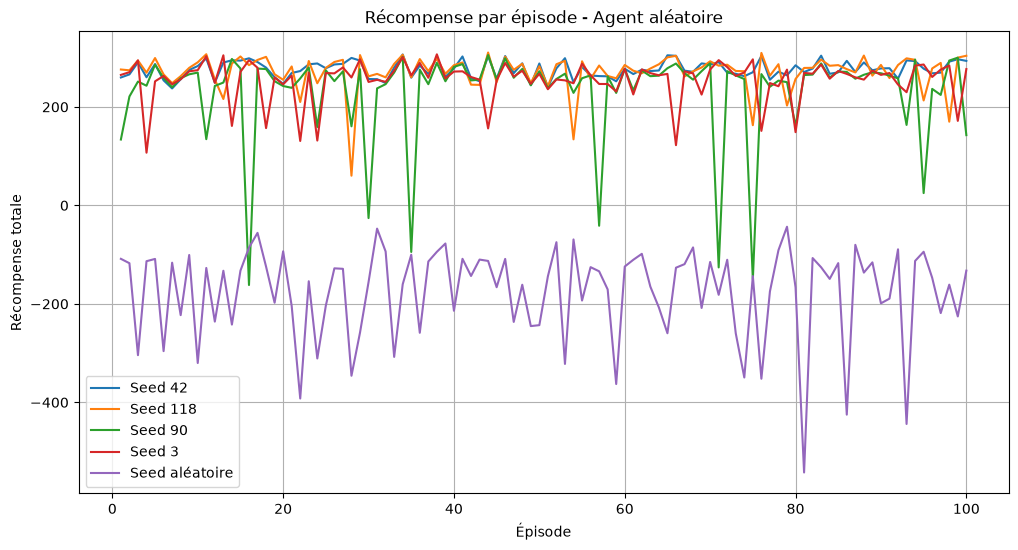

In [177]:
# Création du graphique
plt.figure(figsize=(12, 6))

for k in seeds:
    # Lecture du fichier CSV
    with open(f"results_DQN_evaluation_{k}.csv", "r", encoding="utf-8") as file:
        # On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les récompenses par épisode)
        episode = []
        rewards = []

        reader = csv.DictReader(file)

        # Pour chaque ligne du CSV, on ajoute l'épisode et la récompense associée, à la liste    
        for row in reader:
            episode.append(int(row["episode"]))
            rewards.append(float(row["reward"]))

    plt.plot(episode, rewards, label=f"Seed {k}")


# Ordonnées episodes, Abscisses récompenses

plt.plot(episodes_aléatoire, rewards_aléatoire, label="Seed aléatoire")

# Légende du graphique (titre, label X, label Y)
plt.title("Récompense par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.legend()

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

# Justification des hyperparamètres

Pour son entrainement, le modèle possède de nombreux hyperparamètres. Ces valeurs définisse de quelle manière le réseau de neurone va s'entrainer, de quelle manière il va utiliser et sauvegarder ses données etc.

### <b><u>Liste des Hyperparamètres</u></b> : 

- Epsilon ε
- Gamma γ
- 

# Conclusion Et Bilan

Dans cette section nous allons conclure la partie DQN, résumé et faire un Bilan générales des entrainements et des résultats obtenus.

Le modèle <b>DQN (Deep Q-Network)</b>, comme dit au début, est un algorithme d'apprentissage par renforcement (Deep Reinforcement Learning). Il combine le Q-learning traditionnel avec les réseaux de neurones profonds. 
Ici notre but à été de l'utiliser afin de faire attérir un module lunaire depuis l'environnement <u>"LunarLander-v3"</u> 
Cet environnement possédait 4 actions d'entrées et renvoyait 8 éléments de sorties

Ses actions d'entrées étaients : 

- Ne rien faire
- Activer propulseur droit
- Activer propulseur gauche
- Activer propulseur centrale

Et ses éléments de sorties étaient :

- Sa position horizontale
- Sa position verticale
- Sa vitesse horizontale
- Sa vitesse verticale
- L'angle de son attérisseur (son angle par rapport à l'horizontal)
- Sa vitesse angulaire 
- Le contact de sa jambe droite
- Le contact de sa jambe gauche

L'entrainement du modèle DQN passait par de nombreuses étapes : 

- La Création de l'envionnement Pytorch
    - Cette partie permettait de créer le réseaux de neurones gérés par la librairie PyTorch qui allait donnés tous les outils d'apprentissage à notre modèle.
    - C'est dans cette partie que l'on à défini notre modèle DQN
- L'Epsilon-Greedy
    - C'est la fonction qui donne au modèle sa façon d'apprendre. Il est géré par l'hyperparamètre Epsilon ε qui oscille entre 0 et 1. 
    - C'est la probabilité qu'il effectue une action aléatoirement ou une action grâce à son entrainement.
- Le Replay Buffer
    - C'est la "mémoire" du modèle. Lors de son entrainement, c'est lui qui va se charger de récupérer des actions passées pour lui permettre de savoir ce qu'il a pu déjà faire et ce qui à marché ou non.
    - Elle choisi les échantillons aléatoirement pour éviter au modèle de tendre vers une méthode qui n'est pas correct, en étant bloqué en utilisant seulement des actions récentes.
- La fonction de perte (MSE)
    - Elle permet de garantir que le modèle ne divague pas de son objectif.
    - Elle vient comparer la valeur supposé avec la valeur véritable obtenue, et permet de lisser le modèle actuel pour l'éviter de trop dévier vers une méthode trop éloigné du reste.
- L'optimiseur (Adam)
    - Notre optimiseur permet de corriger très légèrement le modèle actuel dans la fonction de perte.
    - C'est lui qui s'occupe de moduler les actions prises par le module et leurs conséquences futures.

Le modèle fonctionne par système de récompenses. C'est ce qu'on appelle un RLHF (Reinforcement Learning from Human Feedback), le réseaux de neuronne va s'adapter en fonction des récompenses que nous, les humains choisissons de lui donner. Il y a 2 types de récompenses et 8 possibilités de récompenses : 

- Une augmentation des points si le module se rapproche du palier d'atterissage et une diminution s'il s'en éloigne
- Une augmentation des points si le module se déplace lentement et une diminution s'il va trop vite
- Une diminution si l'atterrisseur est trop incliné par rapport à l'horizontale
- +10 points si les jambes du modules sont posées sur le sol
- -0.03 points pour chaque activation des moteurs latéraux
- -0.3 points pour chaque activation du moteurs centrale
- -100 points si le module se crash

L'entrainement du module se passe via ce que l'on appelle des "épisodes", chaque épisodes à une limite de 1000 pas pour être terminé, mais ils existent 4 façon de terminer un épisode :

- Le crash
- La sortie de l'écran
- Le module a attéri correctement
- Le module à mis trop de temps (1000 pas)

Chaque épisode, l'environnement ou se déplace le module spatial est réinitialisé afin qu'il puisse s'entrainer sur différents types de terrains et différentes positions de départs

À chaque étape, à chaque pas, le modèle produit se qu'on appelle une expérience, celle-ci se défini par 5 éléments : 

- state : l'état où il se trouvait avant de bouger
- action : l'action qu'il a choisi pour passer à la prochaine position
- reward : la récompense qu'il a réçu pour être arrivé dans son nouvel état via son action
- next_state : l'état ou se trouve désormais l'agent (donc les 8 paramètres de sorties)
- done : la condition qui permet de savoir si le modèle à terminer d'une des 4 façons l'épisode.